# 05 Final evaluation

**Order matters.** Everything that could still change the model is done first, on the dev set only:

- **A.** Leakage checks on dev (a gate: if one fails, stop before set-c)
- **B.** Choose the decision threshold on dev out-of-fold predictions
- **C.** Freeze the model and threshold (hash + JSON)

Then, **one time only**, on the test set (set-c):

- **D.** Discrimination vs SAPS-I and SOFA
- **E.** Calibration
- **F.** Performance at the frozen threshold
- **G.** Subgroups (age, gender, ICU type)
- **H.** Explainability (SHAP)

Nothing is re-tuned after set-c has been scored. If something looks off, it is reported, not fixed.

In [1]:
# ── Cell 1: setup (dev only for now) ────────────────────────────────
# INSIGHTS
# - The test rows are kept aside in a separate frame and not used until section D.
# - Result: final model = unweighted logistic regression, C = 0.03. Dev OOF AUROC 0.867
#   on 7,990 stays. Set-c rows are held in _test_held and untouched until cell 7.
import sys
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.optimize import minimize_scalar
from scipy.special import expit, logit
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, brier_score_loss)

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
MODELS = ROOT / "models"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src import models as M

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
LABEL = M.LABEL

table = pd.read_parquet(PROCESSED / "features.parquet")
empty = M.empty_stay_mask(table)
dev = table[(table["split"] == "dev") & ~empty].reset_index(drop=True)
_test_held = table[(table["split"] == "test")].reset_index(drop=True)   # untouched until D
del table

model = joblib.load(MODELS / "final_model.joblib")
meta = json.loads((MODELS / "final_model.json").read_text())
FEATURES = meta["features"]
oof = pd.read_parquet(PROCESSED / "oof_predictions.parquet")
assert (oof["RecordID"].values == dev["RecordID"].values).all()
p_oof = oof["LogReg (unweighted)"].values
y_dev = dev[LABEL].values
print(f"Final model: {meta['model']}  params {meta['params']}")
print(f"Dev (modeling set): {len(dev):,} stays, OOF AUROC {roc_auc_score(y_dev, p_oof):.3f}")

Final model: LogReg (unweighted)  params {'model__C': 0.03}
Dev (modeling set): 7,990 stays, OOF AUROC 0.867


## A. Leakage checks on dev

In [2]:
# ── Cell 2: A1. time window and forbidden columns ──────────────────
# INSIGHTS
# - Every measurement used must come from the first 48 h (minute <= 2880).
# - Columns known only after the outcome (Length_of_stay, Survival) and the baseline
#   scores (SAPS-I, SOFA) must not be features. RecordID, set, split, fold must not either.
# - Result: latest measurement is exactly 2,880 min; no forbidden column among the 225 features.
long = pd.read_parquet(PROCESSED / "long.parquet", columns=["RecordID", "minutes", "Parameter"])
max_min = long.groupby("RecordID")["minutes"].max()
print(f"Latest measurement in any stay: {max_min.max()} min (limit 2880)")
FORBIDDEN = {"Length_of_stay", "Survival", "SAPS-I", "SOFA", "RecordID", "set", "split", "fold", LABEL}
leaks = FORBIDDEN & set(FEATURES)
print("Forbidden columns among features:", leaks or "none")
assert max_min.max() <= 2880 and not leaks

Latest measurement in any stay: 2880 min (limit 2880)
Forbidden columns among features: none


In [3]:
# ── Cell 3: A2. do deaths simply have less data? ────────────────────
# INSIGHTS
# - Risk: if patients who die early stop being measured, then "last time measured" or
#   counts would encode "died before 48 h". That would be leakage through the back door.
# - Check on dev: when is the last measurement, by outcome? And how many deaths have
#   Survival <= 2 days?
# - Result: no back-door leak. Median last measurement 47.5 h (survivors) vs 47.6 h
#   (deaths). 166 deaths have Survival <= 2 days, but their data still runs to 47.5 h
#   (the dataset only includes stays of at least 48 h). Data ending before 40 h:
#   survivors 1.05%, deaths 0.80%, so counts are not a proxy for dying early.
from src.data_io import read_outcomes
RAW = ROOT / "data" / "raw"
out_dev = pd.concat([read_outcomes(RAW, s) for s in ["a", "b"]])
ts = long[~long["Parameter"].isin(["RecordID", "Age", "Gender", "Height", "ICUType"]) & long["Parameter"].notna()]
last_t = ts.groupby("RecordID")["minutes"].max().rename("last_minute")
d = dev[["RecordID", LABEL]].merge(last_t, on="RecordID").merge(out_dev[["RecordID", "Survival"]], on="RecordID")
summary = d.groupby(LABEL)["last_minute"].describe(percentiles=[.05, .5])[["count", "5%", "50%", "mean"]]
summary.index = ["survived", "died"]
display((summary / [1, 60, 60, 60]).round(2).rename(columns={"5%": "5% (h)", "50%": "median (h)", "mean": "mean (h)"}))
early = d[(d[LABEL] == 1) & d["Survival"].between(0, 2)]
print(f"Deaths with Survival <= 2 days: {len(early)} of {d[LABEL].sum()}; "
      f"their median last measurement: {early['last_minute'].median() / 60:.1f} h")
print(f"Stays whose data ends before 40 h: survived {(d.loc[d[LABEL]==0, 'last_minute'] < 2400).mean():.2%}, "
      f"died {(d.loc[d[LABEL]==1, 'last_minute'] < 2400).mean():.2%}")
del long, ts

,count,5% (h),median (h),mean (h)
survived,6868.0,46.30,47.53,47.25
died,1122.0,46.52,47.58,47.37


Deaths with Survival <= 2 days: 166 of 1122; their median last measurement: 47.5 h
Stays whose data ends before 40 h: survived 1.05%, died 0.80%


In [4]:
# ── Cell 4: A3. label-shuffle test and single-feature check ─────────
# INSIGHTS
# - Shuffle the labels, refit the same pipeline with the same folds: AUROC must fall to
#   about 0.5. If it stays high, the pipeline is leaking information somehow.
# - No single feature should be "too good" (univariate AUROC > 0.9 would be a red flag).
# - Result: shuffled-label AUROC 0.502, 0.507, 0.495 (chance, as it should be). Strongest
#   single feature GCS_last 0.747, nothing suspiciously strong. GATE PASSED.
X_dev, folds = dev[FEATURES], dev["fold"].values
rng = np.random.default_rng(42)
shuffle_auc = []
for r in range(3):
    y_shuf = rng.permutation(y_dev)
    p = np.zeros(len(dev))
    for k in range(5):
        tr, te = folds != k, folds == k
        m = clone(model).fit(X_dev[tr], y_shuf[tr])
        p[te] = m.predict_proba(X_dev[te])[:, 1]
    shuffle_auc.append(roc_auc_score(y_shuf, p))
print("AUROC with shuffled labels (3 repeats):", np.round(shuffle_auc, 3))

uni = {f: roc_auc_score(y_dev[dev[f].notna()], dev[f].dropna()) for f in FEATURES if dev[f].nunique() > 1}
uni = pd.Series({f: max(a, 1 - a) for f, a in uni.items()}).sort_values(ascending=False)
print(f"Strongest single feature on dev: {uni.index[0]} ({uni.iloc[0]:.3f})")
GATE_OK = max(abs(a - 0.5) for a in shuffle_auc) < 0.05 and uni.iloc[0] < 0.9
print("LEAKAGE GATE:", "PASSED, continue" if GATE_OK else "FAILED, stop here")
assert GATE_OK

AUROC with shuffled labels (3 repeats): [0.502 0.507 0.495]


Strongest single feature on dev: GCS_last (0.747)
LEAKAGE GATE: PASSED, continue


## B. Decision threshold (dev out-of-fold predictions only)

In [5]:
# ── Cell 5: choose the threshold on dev ─────────────────────────────
# INSIGHTS
# - Primary rule (stated before testing): the highest threshold that still catches at
#   least 80% of deaths on dev (sensitivity >= 0.80). In an ICU, missing a patient who is
#   going to die is costlier than reviewing a false alarm.
# - Youden (max sensitivity + specificity - 1) and F1-max shown for comparison only.
# - SAPS-I gets its own 80%-sensitivity threshold on dev, for a fair comparison in F.
# - Result: frozen threshold 0.139 (sensitivity >= 0.80 rule): on dev sens 0.800, spec 0.775,
#   PPV 0.368, NPV 0.960, flags 30.6% of stays. Youden lands nearby (0.128); F1-max is
#   0.262 (sens 0.605, PPV 0.484). The default 0.5 would catch only 31.9% of deaths.
#   SAPS-I needs score >= 13 for 80% sensitivity, which flags 67% of stays (PPV 0.176).
def at_threshold(y, p, t):
    pred = p >= t
    tp = int((pred & (y == 1)).sum()); fp = int((pred & (y == 0)).sum())
    fn = int((~pred & (y == 1)).sum()); tn = int((~pred & (y == 0)).sum())
    return {"threshold": t, "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp),
            "PPV": tp / max(tp + fp, 1), "NPV": tn / max(tn + fn, 1),
            "flagged_%": (tp + fp) / len(y) * 100, "TP": tp, "FP": fp, "FN": fn, "TN": tn}

def thr_for_sensitivity(y, p, target=0.80):
    cands = np.unique(p)[::-1]                 # from high to low
    for t in cands:
        if ((p >= t) & (y == 1)).sum() / (y == 1).sum() >= target:
            return float(t)

fpr, tpr, thr = roc_curve(y_dev, p_oof)
t_youden = float(thr[np.argmax(tpr - fpr)])
prec, rec, thr_pr = precision_recall_curve(y_dev, p_oof)
f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
t_f1 = float(thr_pr[np.argmax(f1)])
t_sens80 = thr_for_sensitivity(y_dev, p_oof, 0.80)

rows = []
for name, t in [("sensitivity >= 0.80 (PRIMARY)", t_sens80), ("Youden", t_youden), ("F1-max", t_f1), ("0.5 (default)", 0.5)]:
    rows.append({"rule": name, **at_threshold(y_dev, p_oof, t)})
thr_table = pd.DataFrame(rows).set_index("rule")
display(thr_table.round(3))

saps_dev = oof["SAPS-I (raw score)"].values
ok = ~np.isnan(saps_dev)
t_saps80 = thr_for_sensitivity(y_dev[ok], saps_dev[ok], 0.80)
print(f"SAPS-I threshold for >= 80% sensitivity on dev: score >= {t_saps80:.0f}")
display(pd.DataFrame([at_threshold(y_dev[ok], saps_dev[ok], t_saps80)]).round(3))

,threshold,sensitivity,specificity,PPV,NPV,flagged_%,TP,FP,FN,TN
rule,,,,,,,,,,
sensitivity >= 0.80 (PRIMARY),0.139,0.800,0.775,0.368,0.960,30.551,898,1543,224,5325
Youden,0.128,0.824,0.758,0.358,0.964,32.353,925,1660,197,5208
F1-max,0.262,0.605,0.895,0.484,0.933,17.547,679,723,443,6145
0.5 (default),0.500,0.319,0.973,0.657,0.897,6.821,358,187,764,6681


SAPS-I threshold for >= 80% sensitivity on dev: score >= 13


,threshold,sensitivity,specificity,PPV,NPV,flagged_%,TP,FP,FN,TN
0,13.0,0.839,0.358,0.176,0.932,66.959,903,4218,173,2354


## C. Freeze the model and the threshold

In [6]:
# ── Cell 6: freeze ──────────────────────────────────────────────────
# INSIGHTS
# - The SHA-256 hash is a fingerprint of the saved model file. It is checked again right
#   before scoring set-c, to prove the model did not change.
# - The threshold is written into models/final_model.json before set-c is touched.
# - Result: threshold 0.1394 and model SHA-256 (084b6963...) written to models/final_model.json.
model_hash = hashlib.sha256((MODELS / "final_model.joblib").read_bytes()).hexdigest()
meta["threshold"] = {"value": t_sens80, "rule": "highest threshold with sensitivity >= 0.80 on dev OOF",
                     "dev_metrics": {k: round(float(v), 4) for k, v in thr_table.iloc[0].items()
                                     if k in ("sensitivity", "specificity", "PPV", "NPV", "flagged_%")}}
meta["saps_threshold_sens80_dev"] = t_saps80
meta["model_sha256"] = model_hash
(MODELS / "final_model.json").write_text(json.dumps(meta, indent=2))
print(f"Frozen threshold: {t_sens80:.4f}")
print(f"Model SHA-256: {model_hash[:16]}...")

Frozen threshold: 0.1394
Model SHA-256: 084b6963e7585fac...


## D. Test set (set-c): scored once

In [7]:
# ── Cell 7: D. discrimination on set-c ─────────────────────────────
# INSIGHTS
# - The model hash is checked first. The empty stays in set-c are excluded (and counted),
#   as decided in Phase 3.
# - SAPS-I recalibrated = one-feature logistic regression fitted on ALL dev stays.
# - Result: 3 empty test stays excluded (0 deaths). Test: 3,997 stays, 585 deaths (14.64%).
#   Model AUROC 0.879 [0.864, 0.892], AUPRC 0.564 [0.523, 0.606]. SAPS-I 0.658 / 0.251,
#   SOFA 0.636 / 0.254. Model minus SAPS-I: +0.221 AUROC [+0.197, +0.244],
#   +0.310 AUPRC [+0.270, +0.350], better in all 2,000 resamples. Test is slightly
#   better than dev OOF (0.867 -> 0.879), so there is no sign of overfitting.
assert hashlib.sha256((MODELS / "final_model.joblib").read_bytes()).hexdigest() == model_hash
test_empty = M.empty_stay_mask(_test_held)
print(f"Test stays: {len(_test_held):,}; excluded with no measurements: {test_empty.sum()} "
      f"(deaths among them: {_test_held.loc[test_empty, LABEL].sum()})")
test = _test_held[~test_empty].reset_index(drop=True)
y = test[LABEL].values
p_model = model.predict_proba(test[FEATURES])[:, 1]

saps_ok_dev = dev["SAPS-I"].notna()
recal = LogisticRegression().fit(dev.loc[saps_ok_dev, ["SAPS-I"]], dev.loc[saps_ok_dev, LABEL])
has_saps = test["SAPS-I"].notna().values
p_saps_recal = np.full(len(test), np.nan)
p_saps_recal[has_saps] = recal.predict_proba(test.loc[has_saps, ["SAPS-I"]])[:, 1]

PRED = {"Model (LogReg)": p_model, "SAPS-I": test["SAPS-I"].values, "SOFA": test["SOFA"].values}
def disc_table(mask):
    rows = []
    for name, p in PRED.items():
        ok = mask & ~np.isnan(p)
        s = M.summarise(y[ok], p[ok])
        rows.append({"score": name, "n": s["n"], "deaths": int(y[ok].sum()),
                     "AUROC": f"{s['AUROC']:.3f} [{s['AUROC_lo']:.3f}, {s['AUROC_hi']:.3f}]",
                     "AUPRC": f"{s['AUPRC']:.3f} [{s['AUPRC_lo']:.3f}, {s['AUPRC_hi']:.3f}]"})
    return pd.DataFrame(rows)
print(f"Test: {len(test):,} stays, {y.sum()} deaths ({y.mean():.2%}), AUPRC floor {y.mean():.3f}")
print("All test stays:")
display(disc_table(np.ones(len(test), bool)))
print("Test stays with a SAPS-I score (like-for-like):")
display(disc_table(has_saps))

rows = []
for base in ["SAPS-I", "SOFA"]:
    ok = has_saps & ~np.isnan(PRED[base])
    for metric, mname in [(roc_auc_score, "AUROC"), (average_precision_score, "AUPRC")]:
        dlt, lo, hi, pw = M.paired_bootstrap_diff(y[ok], p_model[ok], PRED[base][ok], metric, n=2000)
        rows.append({"comparison": f"Model minus {base}", "metric": mname, "difference": round(dlt, 3),
                     "95% CI": f"[{lo:+.3f}, {hi:+.3f}]", "resamples where model not better": pw})
display(pd.DataFrame(rows))
print(f"Dev OOF AUROC {roc_auc_score(y_dev, p_oof):.3f} -> test {roc_auc_score(y, p_model):.3f};  "
      f"AUPRC {average_precision_score(y_dev, p_oof):.3f} -> {average_precision_score(y, p_model):.3f}")

Test stays: 4,000; excluded with no measurements: 3 (deaths among them: 0)
Test: 3,997 stays, 585 deaths (14.64%), AUPRC floor 0.146
All test stays:


,score,n,deaths,AUROC,AUPRC
0,Model (LogReg),3997,585,"0.879 [0.864, 0.892]","0.564 [0.523, 0.606]"
1,SAPS-I,3834,555,"0.658 [0.634, 0.679]","0.251 [0.221, 0.284]"
2,SOFA,3878,568,"0.636 [0.614, 0.659]","0.254 [0.227, 0.287]"


Test stays with a SAPS-I score (like-for-like):


,score,n,deaths,AUROC,AUPRC
0,Model (LogReg),3834,555,"0.879 [0.865, 0.891]","0.561 [0.516, 0.604]"
1,SAPS-I,3834,555,"0.658 [0.634, 0.679]","0.251 [0.221, 0.284]"
2,SOFA,3769,541,"0.641 [0.617, 0.667]","0.253 [0.224, 0.289]"


,comparison,metric,difference,95% CI,resamples where model not better
0,Model minus SAPS-I,AUROC,0.221,"[+0.197, +0.244]",0.0
1,Model minus SAPS-I,AUPRC,0.310,"[+0.270, +0.350]",0.0
2,Model minus SOFA,AUROC,0.239,"[+0.215, +0.263]",0.0
3,Model minus SOFA,AUPRC,0.306,"[+0.268, +0.344]",0.0


Dev OOF AUROC 0.867 -> test 0.879;  AUPRC 0.550 -> 0.564


,n,mean predicted,observed,intercept,slope,Brier,Brier skill
"Model (LogReg), all test",3997.0,0.1439,0.1464,0.0304,0.9460,0.0890,0.2879
"Model (LogReg), SAPS-I subset",3834.0,0.1439,0.1448,0.0101,0.9459,0.0883,0.2868
SAPS-I recalibrated,3834.0,0.1430,0.1448,0.0147,0.9821,0.1181,0.0459


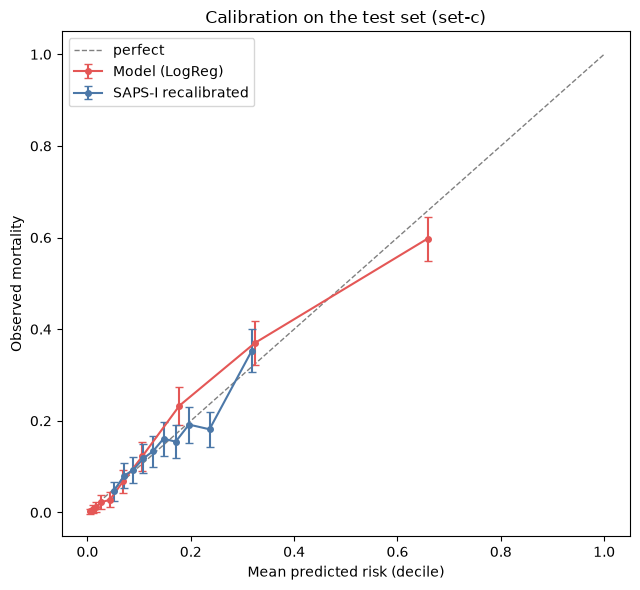

In [8]:
# ── Cell 8: E. calibration on set-c ────────────────────────────────
# INSIGHTS
# - Calibration intercept ("calibration-in-the-large"): 0 = right on average;
#   > 0 = predictions too low overall, < 0 = too high.
# - Calibration slope: 1 = ideal; < 1 = predictions too extreme (overfitting);
#   > 1 = too timid.
# - Brier skill = 1 - Brier / Brier of always predicting the base rate.
# - Result: well calibrated. Mean predicted 14.39% vs observed 14.64%, intercept +0.03
#   (ideal 0), slope 0.95 (ideal 1, slightly too extreme). Brier 0.089, Brier skill 0.29
#   vs SAPS-I recalibrated 0.118 / 0.05. The top decile is a bit over-predicted
#   (66% predicted vs 60% observed).
def calib_stats(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    lp = logit(p)
    slope = LogisticRegression(C=np.inf).fit(lp.reshape(-1, 1), y).coef_[0, 0]
    nll = lambda a: -np.mean(y * np.log(expit(a + lp)) + (1 - y) * np.log(1 - expit(a + lp)))
    intercept = minimize_scalar(nll, bounds=(-3, 3), method="bounded").x
    brier = brier_score_loss(y, p)
    return {"n": len(y), "mean predicted": p.mean(), "observed": y.mean(),
            "intercept": intercept, "slope": slope, "Brier": brier,
            "Brier skill": 1 - brier / (y.mean() * (1 - y.mean()))}

cal = pd.DataFrame({
    "Model (LogReg), all test": calib_stats(y, p_model),
    "Model (LogReg), SAPS-I subset": calib_stats(y[has_saps], p_model[has_saps]),
    "SAPS-I recalibrated": calib_stats(y[has_saps], p_saps_recal[has_saps]),
}).T
display(cal.round(4))

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="perfect")
for name, yy, pp, col in [("Model (LogReg)", y, p_model, "#E45756"),
                          ("SAPS-I recalibrated", y[has_saps], p_saps_recal[has_saps], "#4C78A8")]:
    frac, mean_p = calibration_curve(yy, pp, n_bins=10, strategy="quantile")
    n_bin = len(yy) / 10
    err = 1.96 * np.sqrt(frac * (1 - frac) / n_bin)
    ax.errorbar(mean_p, frac, yerr=err, marker="o", ms=4, capsize=3, color=col, label=name)
ax.set_xlabel("Mean predicted risk (decile)")
ax.set_ylabel("Observed mortality")
ax.set_title("Calibration on the test set (set-c)")
ax.legend()
plt.tight_layout()
fig.savefig(FIGURES / "05_calibration_test.png", dpi=150)
plt.show()

In [9]:
# ── Cell 9: F. performance at the frozen threshold ─────────────────
# INSIGHTS
# - The threshold was frozen on dev (cell 6). Here it is only applied.
# - Number needed to evaluate (NNE) = 1 / PPV: how many flagged patients a clinician
#   reviews to find one who will die.
# - SAPS-I at its own dev-frozen 80%-sensitivity threshold, for comparison.
# - Result: at the frozen threshold: sensitivity 0.812, specificity 0.796, PPV 0.406,
#   NPV 0.961, 29.3% of stays flagged; 475 of 585 deaths caught, 110 missed, 695 false
#   alarms. NNE 2.5 (review 2.5 flagged patients per death found). SAPS-I at its own
#   80% threshold: specificity 0.344, PPV 0.178, NNE 5.6, flags 68% of stays.
res_model = at_threshold(y, p_model, t_sens80)
cm = pd.DataFrame([[res_model["TN"], res_model["FP"]], [res_model["FN"], res_model["TP"]]],
                  index=["survived (actual)", "died (actual)"], columns=["predicted low risk", "predicted high risk"])
display(cm)
ok = has_saps
res_saps = at_threshold(y[ok], test.loc[ok, "SAPS-I"].values, t_saps80)
res_model_sub = at_threshold(y[ok], p_model[ok], t_sens80)
perf = pd.DataFrame([{"score": "Model, all test", **res_model},
                     {"score": "Model, SAPS-I subset", **res_model_sub},
                     {"score": "SAPS-I, SAPS-I subset", **res_saps}]).set_index("score")
perf["NNE"] = 1 / perf["PPV"]
display(perf[["threshold", "sensitivity", "specificity", "PPV", "NPV", "NNE", "flagged_%"]].round(3))

,predicted low risk,predicted high risk
survived (actual),2717,695
died (actual),110,475


,threshold,sensitivity,specificity,PPV,NPV,NNE,flagged_%
score,,,,,,,
"Model, all test",0.139,0.812,0.796,0.406,0.961,2.463,29.272
"Model, SAPS-I subset",0.139,0.814,0.795,0.402,0.962,2.485,29.291
"SAPS-I, SAPS-I subset",13.000,0.840,0.344,0.178,0.927,5.618,68.284


,group,level,n,deaths,AUROC,AUROC_lo,AUROC_hi,AUPRC,SAPS-I AUROC,O/E,flag,note
0,age,40-59,1055,119,0.907,0.880,0.929,0.582,0.632,1.038,,NaN
1,age,60-69,800,107,0.868,0.831,0.899,0.573,0.659,0.972,,NaN
2,age,70-79,933,144,0.875,0.846,0.900,0.586,0.617,0.983,,NaN
3,age,80+,863,189,0.829,0.796,0.859,0.552,0.648,1.076,,NaN
4,age,<40,346,26,0.925,0.876,0.961,0.504,0.716,0.927,,NaN
5,gender,female,1768,285,0.876,0.855,0.896,0.582,0.649,1.042,,NaN
6,gender,male,2225,300,0.881,0.863,0.899,0.551,0.666,0.997,,NaN
7,gender,unknown,4,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,too small
8,icu,cardiac_surgery,873,46,0.897,0.841,0.942,0.494,0.654,1.050,,NaN
9,icu,coronary,601,71,0.830,0.777,0.874,0.414,0.713,0.974,,NaN


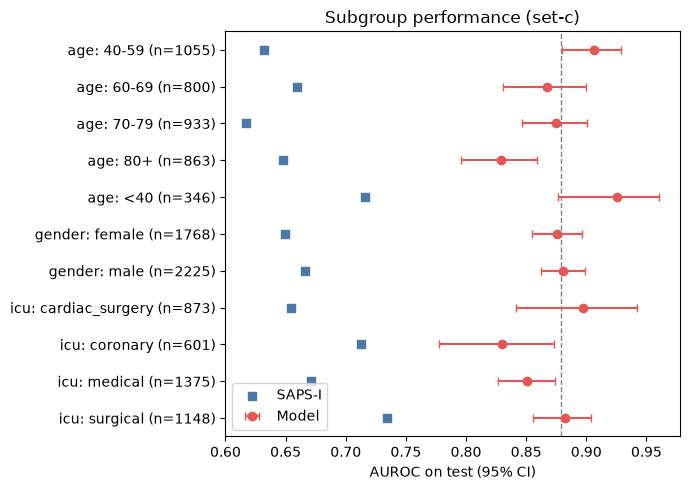

In [10]:
# ── Cell 10: G. subgroups ───────────────────────────────────────────
# INSIGHTS
# - Same frozen model, scored separately per group. CIs widen for small groups.
# - Flag rule (stated in advance): AUROC more than 0.05 below the overall test AUROC, or
#   observed/expected deaths (O/E) outside 0.8 to 1.25.
# - Result: no subgroup is flagged. Weakest: age 80+ (AUROC 0.829 [0.796, 0.859]) and
#   coronary ICU (0.830 [0.777, 0.874]), right at the flag line (0.829). Strongest: <40
#   (0.925) and 40-59 (0.907). O/E between 0.93 and 1.10 everywhere, so calibration holds
#   in every group. The model beats SAPS-I in every subgroup by 0.12 to 0.28 AUROC.
overall_auc = roc_auc_score(y, p_model)
groups = {
    "age": pd.cut(test["Age"], [0, 39, 59, 69, 79, 200], labels=["<40", "40-59", "60-69", "70-79", "80+"]).astype(str),
    "gender": test["Gender"].map({0: "female", 1: "male"}).fillna("unknown"),
    "icu": test[[c for c in test.columns if c.startswith("ICUType_")]].idxmax(axis=1).str.replace("ICUType_", ""),
}
rows = []
for gname, g in groups.items():
    for level in sorted(g.unique()):
        m = (g == level).values
        if m.sum() < 30 or y[m].sum() < 5:
            rows.append({"group": gname, "level": level, "n": int(m.sum()), "deaths": int(y[m].sum()), "note": "too small"})
            continue
        s = M.summarise(y[m], p_model[m])
        sm = m & has_saps
        oe = y[m].sum() / p_model[m].sum()
        flag = (s["AUROC"] < overall_auc - 0.05) or not (0.8 <= oe <= 1.25)
        rows.append({"group": gname, "level": level, "n": s["n"], "deaths": int(y[m].sum()),
                     "AUROC": s["AUROC"], "AUROC_lo": s["AUROC_lo"], "AUROC_hi": s["AUROC_hi"],
                     "AUPRC": s["AUPRC"], "SAPS-I AUROC": roc_auc_score(y[sm], test.loc[sm, "SAPS-I"]),
                     "O/E": oe, "flag": "CHECK" if flag else ""})
sub = pd.DataFrame(rows)
display(sub.round(3))

plot = sub.dropna(subset=["AUROC"]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 5))
ypos = np.arange(len(plot))[::-1]
ax.errorbar(plot["AUROC"], ypos, xerr=[plot["AUROC"] - plot["AUROC_lo"], plot["AUROC_hi"] - plot["AUROC"]],
            fmt="o", color="#E45756", capsize=3, label="Model")
ax.scatter(plot["SAPS-I AUROC"], ypos, marker="s", color="#4C78A8", label="SAPS-I")
ax.axvline(overall_auc, color="grey", ls="--", lw=1)
ax.set_yticks(ypos)
ax.set_yticklabels([f"{g}: {l} (n={n})" for g, l, n in zip(plot["group"], plot["level"], plot["n"])])
ax.set_xlabel("AUROC on test (95% CI)")
ax.set_title("Subgroup performance (set-c)")
ax.legend(loc="lower left")
plt.tight_layout()
fig.savefig(FIGURES / "05_subgroups_test.png", dpi=150)
plt.show()

Background dataset has 7990 samples but max_samples=1000. Subsampling to 1000 samples for SHAP value computation. To use all samples, set max_samples=7990 when initializing the masker.


Top 10 single features (mean |SHAP|):


,mean |SHAP|
GCS_last,0.548
GCS_min,0.309
Age,0.285
BUN_last,0.267
MechVent_ever,0.246
pH_mean,0.229
GCS_mean,0.210
BUN_min,0.196
Na_last,0.189
pH_min,0.187


Top 10 variables, all 6 features summed:


,mean |SHAP|
GCS,0.707
BUN,0.380
RespRate,0.320
Age,0.285
Creatinine,0.272
Urine,0.247
MechVent_ever,0.246
Temp,0.219
HR,0.202
Na,0.194


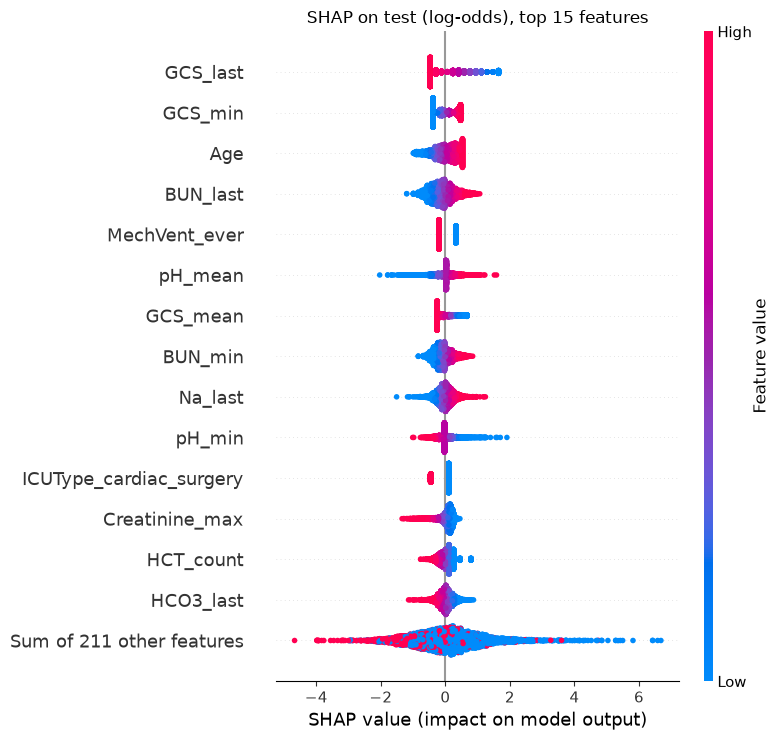

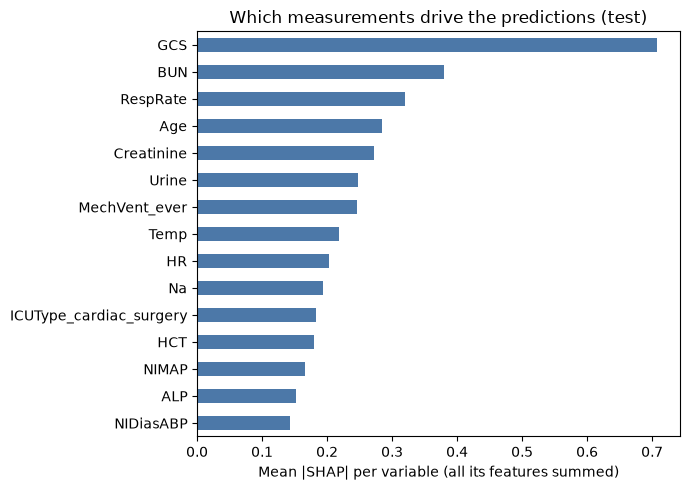

,variable,reference value,coefficient of reference,"corr(total SHAP, value)"
0,GCS,GCS_last,-0.640,-0.935
1,Creatinine,Creatinine_max,-0.245,-0.925
2,BUN,BUN_last,0.338,0.896
3,Urine,Urine_mean,-0.209,-0.642
4,Lactate,Lactate_last,0.202,0.908
5,HCO3,HCO3_last,-0.213,-0.865


Ventilated share by ICU type (test): {'cardiac_surgery': 0.92, 'coronary': 0.43, 'medical': 0.51, 'surgical': 0.68}


In [11]:
# ── Cell 11: H. SHAP explanations ──────────────────────────────────
# INSIGHTS
# - LinearExplainer on the transformed (logged, imputed, scaled) features, with the dev
#   set as background. SHAP values are on the log-odds scale and add up, for each
#   patient, from the average prediction to that patient's prediction.
# - Summing SHAP over the 6 features of one variable (min, max, mean, last, count, has_)
#   gives the variable's total effect, which removes the sign confusion between
#   correlated features seen in Phase 4.
# - Result: by variable (all 6 features summed): GCS 0.707, BUN 0.380, RespRate 0.320,
#   Age 0.285, Creatinine 0.272, Urine 0.247, MechVent_ever 0.246. Summed effects point the
#   clinically expected way for GCS (corr -0.94 with GCS_last), BUN (+0.90), Lactate (+0.91),
#   HCO3 (-0.87), Urine (-0.64). Creatinine is the real oddity: total effect falls as
#   creatinine rises (-0.93) once BUN is in the model (BUN/creatinine ratio effect).
#   MechVent_ever lowers risk because 92% of cardiac-surgery patients are ventilated
#   routinely after the operation (confounding, not a protective effect).
import shap
pre, lr = model[:-1], model[-1]
names = pre.get_feature_names_out()
Xt_dev = pd.DataFrame(pre.transform(dev[FEATURES]), columns=names)
Xt_test = pd.DataFrame(pre.transform(test[FEATURES]), columns=names)
explainer = shap.LinearExplainer(lr, shap.maskers.Independent(Xt_dev, max_samples=1000))
sv = explainer(Xt_test)

imp = pd.Series(np.abs(sv.values).mean(axis=0), index=names).sort_values(ascending=False)
var_of = lambda f: f[4:] if f.startswith("has_") else (f.rsplit("_", 1)[0] if f.rsplit("_", 1)[-1] in ("min", "max", "mean", "last", "count") else f)
by_var = pd.DataFrame(sv.values, columns=names).T.groupby(var_of).sum().T
var_imp = by_var.abs().mean().sort_values(ascending=False)
print("Top 10 single features (mean |SHAP|):"); display(imp.head(10).round(3).to_frame("mean |SHAP|"))
print("Top 10 variables, all 6 features summed:"); display(var_imp.head(10).round(3).to_frame("mean |SHAP|"))

plt.figure()
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("SHAP on test (log-odds), top 15 features")
plt.tight_layout()
plt.savefig(FIGURES / "05_shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
var_imp.head(15)[::-1].plot.barh(ax=ax, color="#4C78A8")
ax.set_xlabel("Mean |SHAP| per variable (all its features summed)")
ax.set_title("Which measurements drive the predictions (test)")
plt.tight_layout()
fig.savefig(FIGURES / "05_shap_by_variable.png", dpi=150)
plt.show()

# For a linear model, one feature's SHAP is just coefficient x (value - mean), so it keeps
# the coefficient's sign. The useful check is the variable's TOTAL effect (6 features summed)
# against its clinically meaningful value.
rows = []
for var, ref in [("GCS", "GCS_last"), ("Creatinine", "Creatinine_max"), ("BUN", "BUN_last"),
                 ("Urine", "Urine_mean"), ("Lactate", "Lactate_last"), ("HCO3", "HCO3_last")]:
    m = test[ref].notna().values
    rows.append({"variable": var, "reference value": ref,
                 "coefficient of reference": lr.coef_[0, list(names).index(ref)],
                 "corr(total SHAP, value)": np.corrcoef(test.loc[m, ref], by_var.loc[m, var])[0, 1]})
display(pd.DataFrame(rows).round(3))
mv = test["MechVent_ever"] == 1
print("Ventilated share by ICU type (test):",
      test.groupby(groups["icu"])["MechVent_ever"].mean().round(2).to_dict())

A_true_alarm: RecordID 158499, died=1, predicted risk 99.9%, SAPS-I 13.0, age 81, GCS_last 3.0, ICU medical


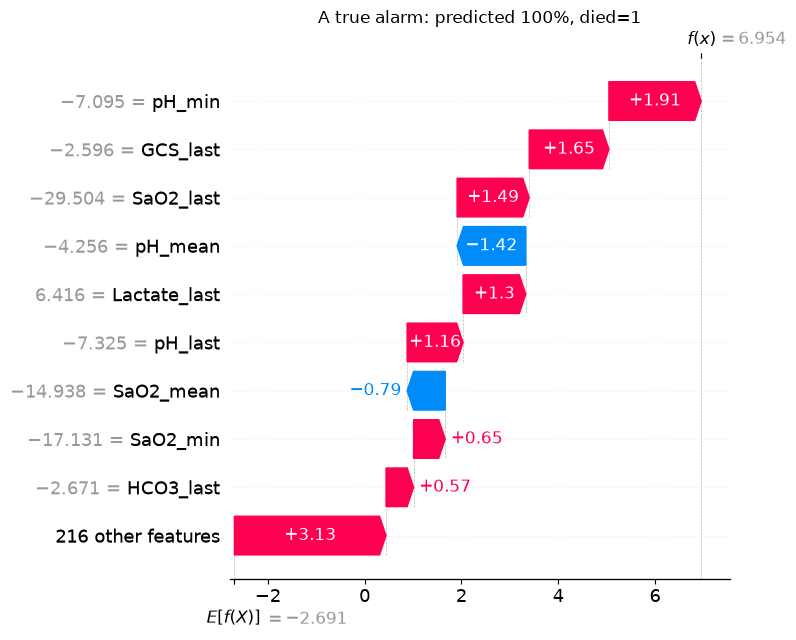

B_missed_death: RecordID 155772, died=1, predicted risk 0.6%, SAPS-I 15.0, age 84, GCS_last 15.0, ICU cardiac_surgery


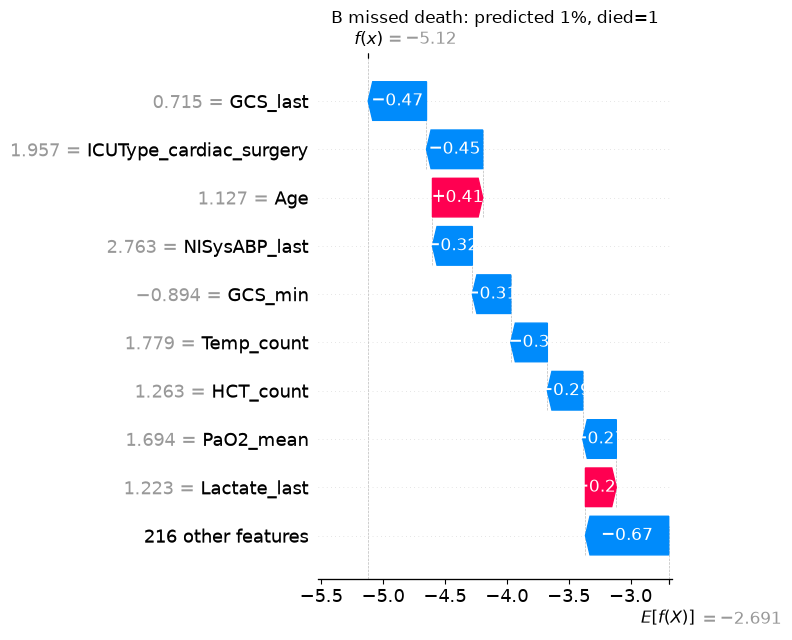

C_false_alarm: RecordID 162780, died=0, predicted risk 96.3%, SAPS-I 23.0, age 56, GCS_last 6.0, ICU coronary


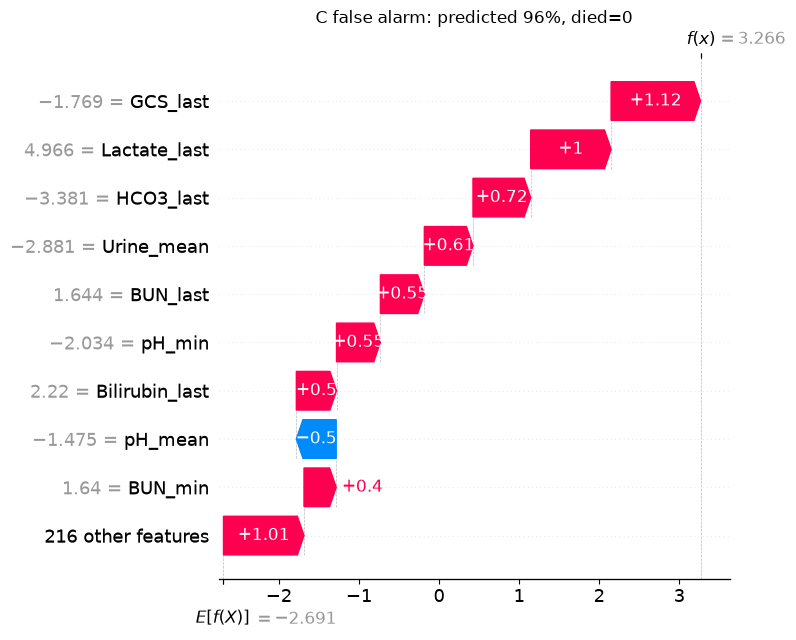

In [12]:
# ── Cell 12: H. three individual patients ──────────────────────────
# INSIGHTS
# - A: correctly flagged death with the highest risk. B: a death the model missed
#   (lowest predicted risk among deaths). C: a false alarm (highest risk among survivors).
# - Waterfall: starts at the average log-odds, each bar is one feature's push up or down.
# - Result: A: medical ICU, age 81, GCS 3, predicted 99.9%, died (SAPS-I only 13).
#   B: cardiac surgery, age 84, GCS 15, predicted 0.6%, died: the model saw a routine
#   post-op patient; the death was not visible in the first 48 h data.
#   C: coronary ICU, age 56, GCS 6, predicted 96.3%, survived (SAPS-I 23, also high).
cases = {
    "A_true_alarm": int(np.argmax(np.where(y == 1, p_model, -1))),
    "B_missed_death": int(np.argmin(np.where(y == 1, p_model, 2))),
    "C_false_alarm": int(np.argmax(np.where(y == 0, p_model, -1))),
}
for tag, i in cases.items():
    r = test.iloc[i]
    print(f"{tag}: RecordID {int(r['RecordID'])}, died={int(y[i])}, predicted risk {p_model[i]:.1%}, "
          f"SAPS-I {r['SAPS-I']}, age {r['Age']:.0f}, GCS_last {r['GCS_last']}, ICU "
          f"{[c[8:] for c in test.columns if c.startswith('ICUType_') and r[c] == 1][0]}")
    plt.figure()
    shap.plots.waterfall(sv[i], max_display=10, show=False)
    plt.title(f"{tag.replace('_', ' ')}: predicted {p_model[i]:.0%}, died={int(y[i])}")
    plt.tight_layout()
    plt.savefig(FIGURES / f"05_shap_patient_{tag}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [13]:
# ── Cell 13: save test predictions and headline metrics ─────────────
# INSIGHTS
# - reports/test_metrics.json holds the final numbers for the README and the demo.
# - Result: saved data/processed/test_predictions.parquet and reports/test_metrics.json.
pred_df = test[["RecordID", LABEL, "SAPS-I", "SOFA"]].copy()
pred_df["p_model"] = p_model
pred_df["p_saps_recal"] = p_saps_recal
pred_df.to_parquet(PROCESSED / "test_predictions.parquet", index=False)

s_all = M.summarise(y, p_model)
s_saps = M.summarise(y[has_saps], test.loc[has_saps, "SAPS-I"].values)
metrics = {
    "test_set": "set-c", "n_test": int(len(test)), "deaths": int(y.sum()),
    "excluded_empty_test_stays": int(test_empty.sum()),
    "model": {k: round(float(v), 4) for k, v in s_all.items() if k != "n"},
    "saps_i_subset_n": int(has_saps.sum()),
    "saps_i": {k: round(float(v), 4) for k, v in s_saps.items() if k not in ("n", "Brier")},
    "calibration_model": {k: round(float(v), 4) for k, v in cal.iloc[0].items()},
    "threshold": {k: (round(float(v), 4) if isinstance(v, float) else v) for k, v in res_model.items()},
}
(ROOT / "reports" / "test_metrics.json").write_text(json.dumps(metrics, indent=2))
print(json.dumps({k: metrics[k] for k in ("n_test", "deaths", "model", "saps_i")}, indent=1))

{
 "n_test": 3997,
 "deaths": 585,
 "model": {
  "AUROC": 0.8788,
  "AUPRC": 0.5644,
  "AUROC_lo": 0.8644,
  "AUROC_hi": 0.8925,
  "AUPRC_lo": 0.5235,
  "AUPRC_hi": 0.6057,
  "Brier": 0.089
 },
 "saps_i": {
  "AUROC": 0.6578,
  "AUPRC": 0.251,
  "AUROC_lo": 0.6337,
  "AUROC_hi": 0.6794,
  "AUPRC_lo": 0.2209,
  "AUPRC_hi": 0.2845
 }
}


## Summary

### The honest final numbers (test set = set-c, 3,997 stays, 585 deaths, scored once)

| | Model (logistic regression) | SAPS-I | SOFA |
|---|---|---|---|
| AUROC | **0.879** [0.864, 0.892] | 0.658 [0.634, 0.679] | 0.636 [0.614, 0.659] |
| AUPRC | **0.564** [0.523, 0.606] | 0.251 [0.221, 0.284] | 0.254 [0.227, 0.287] |
| Brier | 0.089 | 0.118 (recalibrated) | - |

- **Answer to the project question:** yes. From the first 48 h of data, the model predicts in-hospital death much better than SAPS-I: +0.22 AUROC [+0.20, +0.24] and +0.31 AUPRC [+0.27, +0.35] on the same patients (paired bootstrap, better in every resample).
- **No overfitting:** test AUROC (0.879) is in line with the dev cross-validation estimate (0.867).
- **Calibration:** mean predicted 14.4% vs 14.6% observed, intercept +0.03, slope 0.95. Probabilities can be read as risks. The highest-risk decile is slightly over-predicted.
- **At the frozen threshold (0.139, chosen on dev for 80% sensitivity):** 81% of deaths caught, specificity 80%, PPV 41%, NPV 96%, 29% of patients flagged, 2.5 reviews per death found. SAPS-I at the same sensitivity flags 68% of patients with PPV 18%.
- **Subgroups:** no group below the flag line. The weakest are age 80+ and coronary ICU (AUROC 0.83), and calibration holds in all groups.
- **Leakage checks passed:** all data within 48 h, no outcome columns, shuffled labels give AUROC 0.50, and deaths are not simply measured for a shorter time.
- **Explanations:** GCS (consciousness) dominates, then BUN, respiratory-rate pattern, age, creatinine and urine. Two effects need care: ventilation looks protective only because cardiac-surgery patients are routinely ventilated, and creatinine works against BUN (a ratio effect).

### Limitations
1. **One data source, 2012 era:** all three sets come from the same challenge database (one US hospital system). There is no external validation yet. Practice patterns (what gets measured) may differ elsewhere, and the missingness features depend on them.
2. **Prediction at exactly 48 h,** only for stays of at least 48 h. It does not apply to earlier time points or to patients who die or leave sooner.
3. **Age is capped at 90** and some patients are 15 to 17, so the oldest and youngest groups are less precise.
4. **SAPS-I is missing for 4%** of test stays, so the comparison uses the 3,834 stays that have it.
5. **13 stays with no measurements were excluded** (all survivors). In real use, such a patient would need a rule, not this model.
6. **Coefficients and SHAP are associations, not causes** (e.g. the ventilation and creatinine effects).
7. In-hospital death is the only outcome. There is no long-term survival and no information about treatment limitation decisions.

### What would improve it
- External validation on MIMIC-IV (credentialed access), ideally across time periods.
- Trend features (slopes, time since the worst value) or a sequence model, compared fairly with the same CV.
- Recalibrating the top decile if the model were deployed, and tracking calibration over time.
- A prospective check of the threshold with clinicians: is 2.5 reviews per death found acceptable?

**Next (Phase 6):** Streamlit demo, README with these results and limitations, and a clean repo.